In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [79]:
tele = pd.read_csv("./../data/raw/telemetry.csv", parse_dates=["timestamp"])
labels = pd.read_csv("./../data/processed/labels-3.csv", parse_dates=["timestamp"])

df = tele.merge(labels, on=["timestamp", "machine_id"])
df["delta_temp"] = df["spindle_temp"] - df["ambient_temp"]

vib_hi = df["vibration_rms"].quantile(0.9)
temp_hi = df["delta_temp"].quantile(0.9)
flow_lo = df["coolant_flow"].quantile(0.1)
speed_hi = df['spindle_speed'].quantile(0.9)

temp_hi_relaxed = df["delta_temp"].quantile(0.8)      
vib_hi_relaxed = df["vibration_rms"].quantile(0.8)    
flow_lo_relaxed = df["coolant_flow"].quantile(0.15)   
speed_hi_relaxed = df['spindle_speed'].quantile(0.8)

df.head()

,timestamp,machine_id,spindle_temp,ambient_temp,vibration_rms,coolant_flow,feed_rate,spindle_speed,load_pct,power_kw,tool_wear,spindle_overheat,delta_temp
0,2025-01-01 00:00:00,M-A,73.96,24.36,0.871,1.050,0.9,3600,0.294,3.193,0.000,0,49.60
1,2025-01-01 00:05:00,M-A,53.38,22.87,0.536,1.083,1.3,800,0.329,2.149,0.000,0,30.51
2,2025-01-01 00:10:00,M-A,58.12,24.59,0.455,1.025,0.9,1200,0.369,2.457,0.001,0,33.53
3,2025-01-01 00:15:00,M-A,58.08,23.05,0.680,0.977,0.7,1200,0.479,2.702,0.001,0,35.03
4,2025-01-01 00:20:00,M-A,55.37,24.28,0.663,1.072,1.1,800,0.328,2.148,0.001,0,31.09


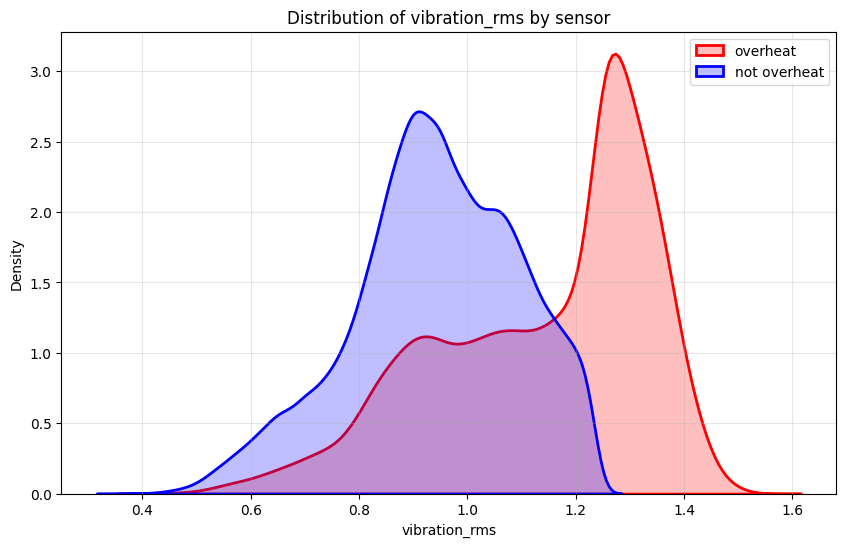

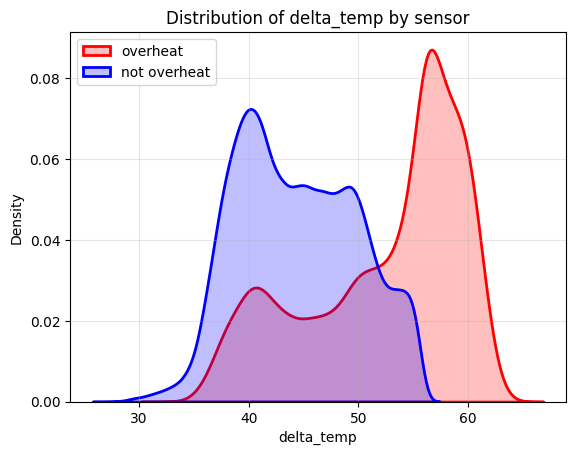

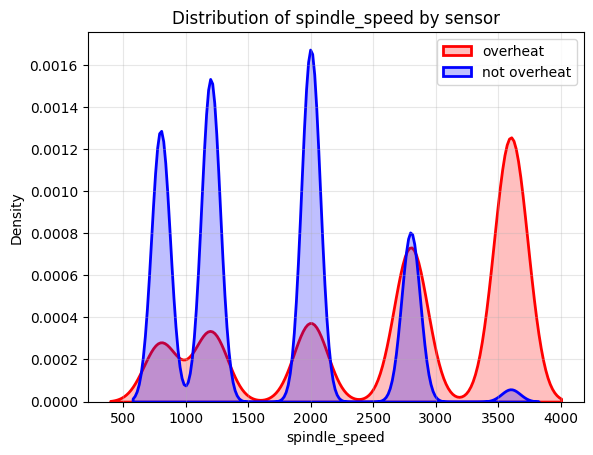

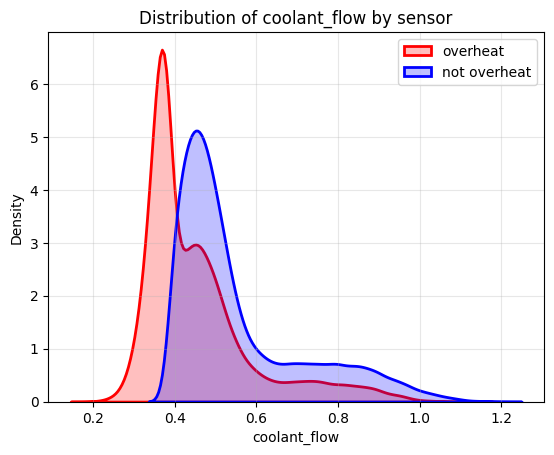

In [80]:
plt.figure(figsize=(10, 6))

for c in ("vibration_rms","delta_temp", "spindle_speed", "coolant_flow"):
    sns.kdeplot(
        data= df.loc[df['spindle_overheat']==1, c],
        label="overheat",
        fill=True,
        alpha=0.25,     # transparency so curves can overlap
        linewidth=2,
        color='red',
    )

    sns.kdeplot(
        data= df.loc[df['spindle_overheat']==0, c],
        label="not overheat",
        fill=True,
        alpha=0.25,     # transparency so curves can overlap
        linewidth=2,
        color='blue',
    )

    plt.title(f"Distribution of {c} by sensor")
    plt.xlabel(f"{c}")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [82]:
print(f"Vibration limit: {vib_hi}")
print(f"Temperature limit: {temp_hi}")
print(f"Spindle speed limit: {speed_hi}")
print(f"Coolant limit: {flow_lo}")
print("#----------------------------------#")
print(f"Vibration limit (relaxed): {vib_hi_relaxed}")
print(f"Temperature limit (relaxed): {temp_hi_relaxed}")
print(f"Spindle speed limit (relaxed): {speed_hi_relaxed}")
print(f"Coolant limit (relaxed): {flow_lo_relaxed}")

Vibration limit: 1.236
Temperature limit: 55.72
Spindle speed limit: 3600.0
Coolant limit: 0.386
#----------------------------------#
Vibration limit (relaxed): 1.147
Temperature limit (relaxed): 52.440000000000005
Spindle speed limit (relaxed): 2800.0
Coolant limit (relaxed): 0.402


In [83]:
actions_df= pd.read_csv("./../data/raw/maintenance.csv", parse_dates=["timestamp"])

In [ ]:
actions_df

,timestamp,machine_id,action_type,duration_h,success
0,2025-01-12,M-C,clean_filter,1.5,1
1,2025-01-13,M-A,replace_bearing,4.0,1
2,2025-01-14,M-B,clean_filter,1.5,1
3,2025-01-15,M-D,replace_bearing,4.0,1
4,2025-01-27,M-B,clean_filter,1.5,1
5,2025-01-28,M-A,clean_filter,1.5,1
6,2025-01-28,M-C,replace_bearing,4.0,1
7,2025-01-29,M-D,clean_filter,1.5,1
8,2025-02-09,M-A,clean_filter,1.5,1
9,2025-02-11,M-C,inspect_fan,2.0,1


In [84]:
actions_df.dtypes

timestamp      datetime64[ns]
machine_id             object
action_type            object
duration_h            float64
success                 int64
dtype: object

In [ ]:
tele.dtypes

timestamp        datetime64[ns]
machine_id               object
spindle_temp            float64
ambient_temp            float64
vibration_rms           float64
coolant_flow            float64
feed_rate               float64
spindle_speed             int64
load_pct                float64
power_kw                float64
tool_wear               float64
dtype: object

In [86]:
actions_df["action_type"].value_counts()

action_type
clean_filter       13
replace_bearing     6
inspect_fan         3
refill_coolant      1
Name: count, dtype: int64

In [87]:
action_map={
    "replace_bearing": "ReplaceBearing",
    "inspect_fan": "RepairFan",
    "clean_filter": "CleanFilter",
    "refill_coolant": "FlushCoolant",
    "P5": "SlowDown",
}

In [88]:
def select_most_concerning_row(sensor_df: pd.DataFrame, machine_id: str, procedure_ts: pd.Timestamp, symptom_fn, n_rows: int = 6):

    # filter by machine and time
    candidates = (
        sensor_df[
            (sensor_df['machine_id'] == machine_id) &
            (sensor_df['timestamp'] < procedure_ts)
        ]
        .sort_values('timestamp', ascending=False)
        .head(n_rows)
        .copy()
    )

    if candidates.empty:
        return None

    # Compute symptoms + scores
    candidates['symptoms'] = candidates.apply(symptom_fn, axis=1)
    candidates['symptom_score'] = candidates['symptoms'].apply(
        lambda d: sum(d.values())
    )
    candidates['time_diff'] = (
        procedure_ts - candidates['timestamp']
    ).dt.total_seconds()

    # Sort by:
    # 1) most symptoms
    # 2) closest in time
    best_row = candidates.sort_values(
        ['symptom_score', 'time_diff'],
        ascending=[False, True]
    ).iloc[0]

    return best_row

In [89]:
def raw2symptoms( raw_data: dict[str, float]) -> dict[str, int]:
    """
    Convert raw telemetry data to symptom variables.
    
    :param raw_data: A dictionary with keys: 'vibration_rms', 'spindle_temp', 'ambient_temp', 'coolant_flow', 'spindle_speed'
    :type raw_data: dict[str, float]
    :return: A dictionary with symptom variables
    :rtype: dict[str, int]
    """
    if vib_hi is None or temp_hi is None or flow_lo is None or speed_hi is None:
        raise ValueError("Model thresholds are not set. Train the model first.")
    
    high_vibration = int(raw_data["vibration_rms"] > vib_hi)
    high_spindle_temp = int((raw_data["spindle_temp"] - raw_data["ambient_temp"]) > temp_hi)
    low_coolant_flow = int(raw_data["coolant_flow"] < flow_lo)
    high_spindle_speed = int(raw_data["spindle_speed"] >= speed_hi)
    
    return {
        "high_vibration": high_vibration,
        "high_spindle_temp": high_spindle_temp,
        "high_spindle_speed": high_spindle_speed,
        "low_coolant_flow": low_coolant_flow,
    }

In [ ]:
results = []

for _, proc in actions_df.iterrows():
    best = select_most_concerning_row(
        sensor_df=tele,
        machine_id=proc['machine_id'],
        procedure_ts=proc['timestamp'],
        symptom_fn=raw2symptoms,
        n_rows=6
    )

    if best is not None:
        results.append({
            'proc_id': action_map[proc['action_type']],
            'machine_id': proc['machine_id'],
            'procedure_timestamp': proc['timestamp'],
            'selected_sensor_timestamp': best['timestamp'],
            'symptom_score': best['symptom_score'],
            'spindle_temp': best["spindle_temp"],
            "ambient_temp": best["ambient_temp"],
            "vibration_rms": best["vibration_rms"],
            "coolant_flow": best["coolant_flow"],
            "spindle_speed": best["spindle_speed"],

        })

result_df = pd.DataFrame(results)


In [93]:
result_df

,proc_id,machine_id,procedure_timestamp,selected_sensor_timestamp,symptom_score,spindle_temp,ambient_temp,vibration_rms,coolant_flow,spindle_speed
0,CleanFilter,M-C,2025-01-12,2025-01-11 23:55:00,1,72.04,21.72,1.177,0.384,2800
1,ReplaceBearing,M-A,2025-01-13,2025-01-12 23:55:00,4,76.95,20.14,1.319,0.381,3600
2,CleanFilter,M-B,2025-01-14,2025-01-13 22:20:00,3,75.13,18.57,1.307,0.401,3600
3,ReplaceBearing,M-D,2025-01-15,2025-01-14 22:50:00,3,77.94,20.62,1.262,0.525,3600
4,CleanFilter,M-B,2025-01-27,2025-01-26 22:50:00,2,74.31,19.73,1.270,0.380,2800
5,CleanFilter,M-A,2025-01-28,2025-01-27 23:40:00,1,59.66,20.38,0.850,0.384,800
6,ReplaceBearing,M-C,2025-01-28,2025-01-27 23:15:00,2,73.85,20.00,1.296,0.374,2800
7,CleanFilter,M-D,2025-01-29,2025-01-28 23:15:00,3,77.60,20.61,1.357,0.508,3600
8,CleanFilter,M-A,2025-02-09,2025-02-08 23:45:00,1,74.28,20.88,1.257,0.449,2800
9,RepairFan,M-C,2025-02-11,2025-02-10 23:25:00,1,63.62,20.75,0.852,0.357,1200


In [ ]:
result_df.to_csv("./../data/actions/procedures.csv")